# Lab 03: How to give an agent memory

**CPU | API key: `OPENAI_API_KEY`**

## Goal

A chat model keeps nothing between calls, so the copilot forgets the customer as soon as the rep asks a follow-up.
In this lab you give it a thread that a checkpointer saves to a file, keep a long thread short, and keep a customer's
email address out of what the thread stores. The moment that teaches it: you restart the kernel, Python has forgotten
every variable, and the conversation is still there, read back from a SQLite file. Then you read what that file
actually holds, and find the address the rep pasted, in plain text.

## What you will learn

- Why a chat model forgets between calls, and how sending the conversation again as a list gives it memory.
- How a checkpointer and a `thread_id` keep each conversation for you.
- How to keep a thread across a kernel restart with `SqliteSaver`, and read what the file holds.
- How to keep a long thread short by trimming or summarising with middleware, and how to test both with a late
  question about an early fact.
- How to keep an email address out of the saved thread with `PIIMiddleware`, and check the file, not the reply.

The lab makes about 85 calls to the chat model: under one US cent with `gpt-4o-mini`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it. You will run both again after the restart in Part C.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


## Coming from

Lab 01 built a tool-calling agent and sent the conversation history by hand. This lab lets a checkpointer keep that
history, in memory and then in a file. The outputs saved here come from `gpt-4o-mini` on 12 Oct 2026; your replies will
be worded differently.

The picture shows one turn on a thread. The **checkpointer** loads the thread's earlier messages before the model is
called and saves the new ones afterwards. Between the two, middleware can trim the messages, summarise the older
ones, or redact an email address.

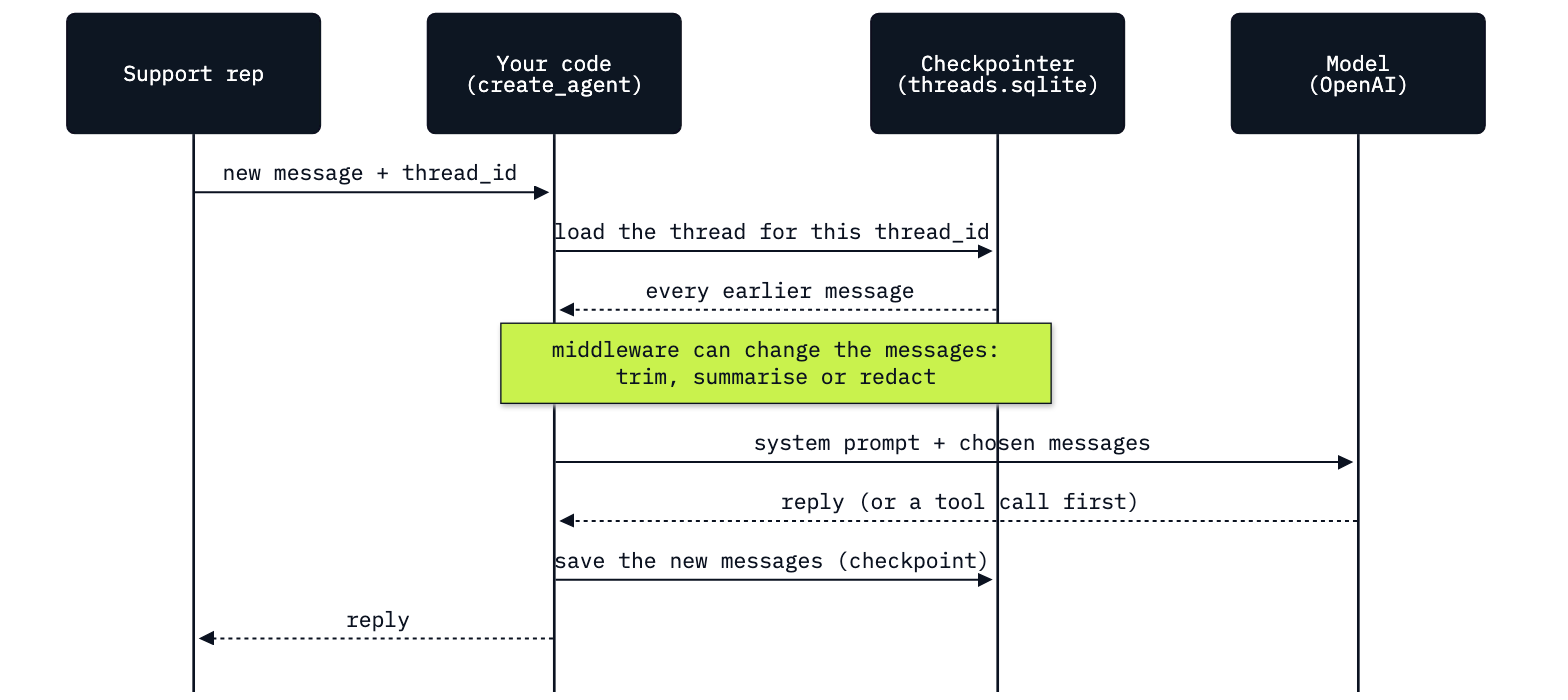

In [3]:
from IPython.display import Image
Image(filename=ROOT / "03_Thread_Memory_Three_Settings" / "resources" / "lab03_thread_turn.png", width=760)

---

## Part A: Send the conversation again yourself

This part shows memory before any library hides it: a list your code keeps and sends again. The first call tells
the model about a customer; the second asks a follow-up and shares nothing with the first.

In [4]:
from shared.settings import chat_model

model = chat_model(settings)
SHORT_PROMPT = "You help Chinook support reps. Keep answers short."

first = model.invoke([("system", SHORT_PROMPT), ("user", "Hi, I have Helena Holý on email. She has 7 invoices.")])
second = model.invoke([("system", SHORT_PROMPT), ("user", "What was her name again?")])
print("call 1:", first.text)
print("call 2:", second.text)

call 1: Got it! What specific assistance do you need with Helena Holý's invoices?
call 2: Could you provide more context or details? That would help me find the right name.


Call 2 answered *Could you provide more context or details? That would help me find the right name.* The model had no idea who "her" was: the second request held the system prompt and one
question, and no customer.

The fix is the one Lab 01 used: keep the conversation in a list, add the model's first reply and the follow-up, and
send the whole list.

In [5]:
conversation = [
    ("system", SHORT_PROMPT),
    ("user", "Hi, I have Helena Holý on email. She has 7 invoices."),
    first,                                   # the model's own reply from call 1
    ("user", "What was her name again?"),
]
third = model.invoke(conversation)
print(len(conversation), "messages sent")
print("call 3:", third.text)

4 messages sent
call 3: Helena Holý.


Four messages sent, and call 3 answered *Helena Holý.* The model and the question are the same; only the list changed.

That is all memory within a conversation is. Your code now owns a list per conversation, the list grows every turn,
and it is gone when Python stops.

### Checkpoint A

| You should see | Our run |
|---|---|
| The follow-up with nothing shared | the model does not know who "her" is |
| The list sent again | 4 messages; the reply names Helena Holý |

---

## Part B: Let a checkpointer keep the thread

This part hands the list to LangGraph, the runtime under LangChain's agent. Two new pieces:

- A **checkpointer** saves the agent's state, its messages, after every step and loads it at the next turn.
  `InMemorySaver` keeps it in this Python process.
- A **`thread_id`** names one conversation. It goes in the config you pass to `invoke`, under `"configurable"`: the
  same id, the same history.

The agent has no tools yet, so each turn is one model call.

In [6]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(model, tools=[], system_prompt=SHORT_PROMPT, checkpointer=InMemorySaver())
helena = {"configurable": {"thread_id": "case-helena-01"}}

result = agent.invoke({"messages": [("user", "Hi, I have Helena Holý on email. She has 7 invoices.")]}, helena)
print(result["messages"][-1].text)

Please provide the details or questions regarding the invoices for Helena Holý, and I can assist you further!


Now send only the follow-up, on the same `thread_id`. Your code sends one new message. Predict: does the agent know
who "her" is?

In [7]:
result = agent.invoke({"messages": [("user", "What was her name again?")]}, helena)
print(result["messages"][-1].text)

Helena Holý.


It answered *Helena Holý.* The checkpointer loaded turn 1, and the agent sent it to the model again with the new
message, as your list did in Part A.

Now the same question on a new `thread_id`.

In [8]:
puja = {"configurable": {"thread_id": "case-puja-01"}}
result = agent.invoke({"messages": [("user", "What was her name again?")]}, puja)
print(result["messages"][-1].text)

Could you provide more details about who you're referring to?


*Could you provide more details about who you're referring to?* Nothing from `case-helena-01` reached this call. Two cases, two threads, and neither sees the other's
messages, which is what you want when a rep switches customers.

`get_state` reads what the checkpointer saved for one `thread_id`.

In [9]:
for message in agent.get_state(helena).values["messages"]:
    print(f"{message.type:5} | {message.text}")

human | Hi, I have Helena Holý on email. She has 7 invoices.
ai    | Please provide the details or questions regarding the invoices for Helena Holý, and I can assist you further!
human | What was her name again?
ai    | Helena Holý.


Four messages: two from the rep (`human` is LangChain's name for the user role) and two replies. The system prompt is
not saved: `create_agent` adds it to every model call, so the prompt lives in your code and the conversation in the
checkpointer.

### Checkpoint B

| You should see | Our run |
|---|---|
| The follow-up on `case-helena-01` | names Helena Holý |
| The same question on `case-puja-01` | does not know who "her" is |
| The saved thread | 4 messages, no system prompt |

---

## Part C: Keep the thread across a restart

This part makes the thread outlive Python. `InMemorySaver` loses its threads when the kernel restarts; `SqliteSaver`
writes them to a SQLite file, and only the `checkpointer=` argument changes (`PostgresSaver` does the same for
servers sharing a database). The file has a fixed path in this lab's folder, `threads.sqlite`, so the next kernel can
find it; `.gitignore` keeps it out of the repository. `check_same_thread=False` lets LangGraph use the connection from
its worker threads. The rep's first message includes the customer's email address, as reps often paste it.

In [10]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

THREADS = ROOT / "03_Thread_Memory_Three_Settings" / "threads.sqlite"
for old_file in THREADS.parent.glob("threads.sqlite*"):
    old_file.unlink()

conn = sqlite3.connect(THREADS, check_same_thread=False)
agent = create_agent(model, tools=[], system_prompt=SHORT_PROMPT, checkpointer=SqliteSaver(conn))
helena = {"configurable": {"thread_id": "case-helena-01"}}

first_message = "I'm handling Helena Holý's emails today. Her address is helena.h@example.com."
result = agent.invoke({"messages": [("user", first_message)]}, helena)
print(result["messages"][-1].text)
print("files:", sorted(path.name for path in THREADS.parent.glob("threads.sqlite*")))

Got it! How can I assist you with her emails today?
files: ['threads.sqlite', 'threads.sqlite-shm', 'threads.sqlite-wal']


The reply: *Got it! How can I assist you with her emails today?* The thread is now in `threads.sqlite`; the `-wal` and `-shm` files are SQLite's own and
belong with it.

### Restart the kernel

⚠️ Restart the kernel now: **Kernel → Restart Kernel** in JupyterLab or VS Code, **Runtime → Restart session** on
Colab. Then run the **Setup** and **Config** cells at the top again, and continue from the next cell. Do not run the
cell above again: it deletes the file.

Predict: after the restart, will the agent still know the customer?

In [11]:
print("Python still has the agent:", "agent" in globals())
print("Python still has Part A's list:", "conversation" in globals())
if "agent" in globals():
    print("⚠️ The kernel was not restarted. Restart it, run Setup and Config, then run this cell again.")

Python still has the agent: False
Python still has Part A's list: False


Both `False`. The restart cleared every variable this notebook made. (If you see the ⚠️ line, restart now: the rest
of this part proves nothing without it.) Build the agent again with the same lines as before the restart, on the
same file, without deleting it, and read the thread.

In [12]:
import sqlite3
from langchain.agents import create_agent
from langgraph.checkpoint.sqlite import SqliteSaver
from shared.settings import chat_model

THREADS = ROOT / "03_Thread_Memory_Three_Settings" / "threads.sqlite"
SHORT_PROMPT = "You help Chinook support reps. Keep answers short."
conn = sqlite3.connect(THREADS, check_same_thread=False)
checkpointer = SqliteSaver(conn)
agent = create_agent(chat_model(settings), tools=[], system_prompt=SHORT_PROMPT, checkpointer=checkpointer)

helena = {"configurable": {"thread_id": "case-helena-01"}}
for message in agent.get_state(helena).values["messages"]:
    print(f"{message.type:5} | {message.text}")

human | I'm handling Helena Holý's emails today. Her address is helena.h@example.com.
ai    | Got it! How can I assist you with her emails today?


The thread is there: two messages, read from the file by a kernel that never saw them. Ask a follow-up.

In [13]:
result = agent.invoke({"messages": [("user", "Which customer am I working on, and what is her address?")]}, helena)
print(result["messages"][-1].text)

You are working on Helena Holý, and her email address is helena.h@example.com.


*You are working on Helena Holý, and her email address is helena.h@example.com.* From here on the file is the thread's memory. On every turn the agent asks the checkpointer for the thread, the checkpointer reads it from
`threads.sqlite`, the agent sends it to the model, and the new state is written back to the file. Nothing about the
conversation is kept in Python between turns. Every agent in Parts D and E uses this `checkpointer`.

### Read what the file stored

The file is an ordinary SQLite database with two tables: `checkpoints` holds a snapshot of the thread's state after
each step of a run, and `writes` holds the update each step made. Count the rows of each that contain the address
(`instr` finds one text inside another; rows are stored as bytes, so the address is searched as bytes).

In [14]:
def rows_holding(text, thread_id):
    """Print how many rows of each table hold the text, for one thread."""
    for table, column in (("checkpoints", "checkpoint"), ("writes", "value")):
        total, found = conn.execute(
            f"SELECT count(*), sum(instr({column}, ?) > 0) FROM {table} WHERE thread_id = ?",
            (text.encode(), thread_id),
        ).fetchone()
        print(f"{table:11} {found or 0} of {total} rows hold {text!r}")

rows_holding("helena.h@example.com", "case-helena-01")

checkpoints 6 of 6 rows hold 'helena.h@example.com'
writes      2 of 6 rows hold 'helena.h@example.com'


All 6 checkpoint rows and 2 of the 6 write rows hold the address. Two turns made 6 checkpoints, because LangGraph saves one after every step so that a run can
resume part-way. The address sits in a plain file on disk that anyone with the file can read. Part E keeps it out.

### Checkpoint C

| You should see | Our run |
|---|---|
| After the restart | `False` for the agent and for Part A's list |
| The saved thread | 2 messages, the address in the first |
| The follow-up | names Helena Holý and her address |
| Rows holding the address | `checkpoints` 6 of 6, `writes` 2 of 6 |

---

## Part D: Keep a long thread short

This part deals with the cost of memory: every turn sends the whole thread again. Now the copilot itself: the
system prompt in `shared/prompts/copilot_system_v1.md`: identity, instructions and examples, the sections you wrote in
Lab 02, but not the file you saved there. It is a fixed version that ships with the repository, so this lab does not
depend on your Lab 02 run (its version comment is cut off). The tool is `get_policy` from Lab 01.

In [15]:
SYSTEM_PROMPT = (ROOT / "shared" / "prompts" / "copilot_system_v1.md").read_text(encoding="utf-8")
SYSTEM_PROMPT = SYSTEM_PROMPT.split("-->", 1)[1].strip()
print(SYSTEM_PROMPT[:200], "...")

# Identity
You are the Chinook support copilot. You help Chinook's support representatives (reps) answer customer emails. You talk to the rep, not to the customer.

# Instructions
- Call get_policy be ...


In [16]:
from langchain.tools import tool

CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))

def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        return f"No policy named {name!r}. Known: {', '.join(POLICIES)}."
    return path.read_text(encoding="utf-8")

policy_tool = tool(get_policy, parse_docstring=True)
print(policy_tool.name, "|", len(POLICIES), "policies")

get_policy | 20 policies


Seven turns of one case. Turn 2 states two facts from `data/chinook.db`: 7 invoices totalling $49.62, and her
assigned rep, Steve Johnson. Turn 7 asks for them back.

In [17]:
TURNS = [
    "Hi, I'm handling Helena Holý's emails today.",
    "For context: she has 7 invoices totalling $49.62, and her assigned rep is Steve Johnson.",
    "She says the Kind of Blue sleeve had a different disc inside. What does policy say?",
    "She would prefer a replacement, not a refund. Is that allowed?",
    "How long until she gets a decision?",
    "Draft a two-sentence reply I can send her.",
    "Before I close the ticket: what is her invoice total, and who is her assigned rep?",
]
FACTS = ["49.62", "Steve Johnson"]

`run_turns` sends them on one thread and prints, after each turn, the messages saved and the input tokens of the
turn's last model call.

In [18]:
def run_turns(agent, thread_id, show=True):
    """Send the seven turns on one thread and return the reply to turn 7."""
    config = {"configurable": {"thread_id": thread_id}}
    for number, text in enumerate(TURNS, start=1):
        result = agent.invoke({"messages": [("user", text)]}, config)
        if show:
            saved = len(agent.get_state(config).values["messages"])
            sent = result["messages"][-1].usage_metadata["input_tokens"]
            print(f"turn {number}: {saved:2} messages saved, {sent:4} input tokens in the last call")
    return result["messages"][-1].text

### Full history

The copilot on Part C's SQLite checkpointer, with no middleware: every turn sends every earlier message, the policy
texts from `get_policy` included.

In [19]:
copilot = create_agent(chat_model(settings), tools=[policy_tool], system_prompt=SYSTEM_PROMPT,
                       checkpointer=checkpointer)
reply = run_turns(copilot, "helena-full")
print(reply)

turn 1:  2 messages saved,  459 input tokens in the last call


turn 2:  4 messages saved,  506 input tokens in the last call


turn 3:  8 messages saved,  643 input tokens in the last call


turn 4: 12 messages saved,  785 input tokens in the last call


turn 5: 14 messages saved,  855 input tokens in the last call


turn 6: 16 messages saved,  923 input tokens in the last call


turn 7: 18 messages saved,  977 input tokens in the last call
Helena's invoice total is $49.62, and her assigned rep is Steve Johnson.


The thread grew to 18 messages, and the last call's input grew from 459 to 977
tokens. Turn 7 answered *Helena's invoice total is $49.62, and her assigned rep is Steve Johnson.*

`run_turns` prints two different numbers. **Messages saved** is what the checkpointer holds for the thread in the
file after the turn. With full history nothing is removed: each turn adds the rep's message and the reply, and a
turn that calls `get_policy` also adds the tool call and the policy text (turns 3 and 4 add four messages each, the others two). **Input tokens** is what
the turn's last call sent: the whole saved thread again, plus the system prompt and the tool's description. The
thread grows because nothing leaves it; the cost grows because all of it is sent.

### Trim a list of messages

To **trim** is to drop the oldest messages before each call. `trim_messages` from `langchain_core` does it on a
list. Try it on a short history first; this calls no model.

In [20]:
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, trim_messages

history = [
    SystemMessage("You help Chinook support reps."),
    HumanMessage("Customer is Helena Holý."), AIMessage("Noted."),
    HumanMessage("7 invoices, $49.62, rep Steve Johnson."), AIMessage("Noted."),
    HumanMessage("She wants a replacement disc."), AIMessage("Ticket 01, waiting on a photo."),
    HumanMessage("What is her invoice total?"),
]
print(len(history), "messages")

8 messages


The arguments:

- `strategy="last"` keeps the newest messages.
- `token_counter=len` counts each message as one, so `max_tokens=5` means five messages (Going further counts tokens).
- `start_on="human"` starts the window on a rep's message, never on a reply whose question was cut off.
- `include_system=True` keeps the system message.

Predict: which messages survive?

In [21]:
kept = trim_messages(history, strategy="last", token_counter=len, max_tokens=5,
                     start_on="human", include_system=True)
for message in kept:
    print(f"{message.type:6} | {message.content}")

system | You help Chinook support reps.
human  | She wants a replacement disc.
ai     | Ticket 01, waiting on a photo.
human  | What is her invoice total?


Four messages, although five were allowed: the newest five started with a *Noted.*, and `start_on="human"` dropped
it. The message with the invoice total is gone, and nothing failed.

### Trim inside the agent

`trim_messages` only shortens a list you give it. To trim a thread, something must run it on the thread's messages
before each model call and keep the result. A `before_model` hook does that. On every model call:

1. the agent loads the thread from `threads.sqlite`;
2. `keep_recent` trims its messages to the newest six;
3. it returns a state update: `RemoveMessage(id=REMOVE_ALL_MESSAGES)` clears the thread's messages and the kept six
   are written back in their place;
4. the model is sent those six, with the system prompt in front (it is not in the saved state, so there is no
   `include_system`);
5. the checkpointer saves the trimmed state to the file as the thread's newest checkpoint.

So the hook trims the **saved thread**, not only this call.

In [22]:
from langchain.agents.middleware import before_model
from langchain_core.messages import RemoveMessage
from langgraph.graph.message import REMOVE_ALL_MESSAGES

@before_model
def keep_recent(state, runtime):
    kept = trim_messages(state["messages"], strategy="last", token_counter=len, max_tokens=6,
                         start_on="human")
    return {"messages": [RemoveMessage(id=REMOVE_ALL_MESSAGES), *kept]}

The same copilot with `middleware=[keep_recent]`, on its own thread.

In [23]:
trim_copilot = create_agent(chat_model(settings), tools=[policy_tool], system_prompt=SYSTEM_PROMPT,
                            middleware=[keep_recent], checkpointer=checkpointer)
reply = run_turns(trim_copilot, "helena-trim")
print(reply)

turn 1:  2 messages saved,  459 input tokens in the last call


turn 2:  4 messages saved,  506 input tokens in the last call


turn 3:  6 messages saved,  627 input tokens in the last call


turn 4:  6 messages saved,  667 input tokens in the last call


turn 5:  6 messages saved,  636 input tokens in the last call


turn 6:  6 messages saved,  625 input tokens in the last call


turn 7:  4 messages saved,  516 input tokens in the last call
I'm unable to access customer details such as invoice totals or assigned reps. Please check your support system for that information.


The thread never held more than 6 messages, and the last call stayed at or below 667 input
tokens. Turn 7 answered *I'm unable to access customer details such as invoice totals or assigned reps. Please check your support system for that information.*

The reply is polite, there is no error, and it is wrong: the rep gave both facts at turn 2, and the trim dropped them.
Check it in code, and run the trimmed copilot twice more on new threads.

In [24]:
def has_facts(reply):
    return [fact for fact in FACTS if fact in reply]

print("run 1:", has_facts(reply))
for run in (2, 3):
    print(f"run {run}:", has_facts(run_turns(trim_copilot, f"helena-trim-{run}", show=False)))

run 1: []


run 2: []


run 3: []


Neither fact in 3 of 3 runs. Only a late question about an early fact shows the problem, so that is the test to write for any
memory setting.

The facts are gone from the thread the agent loads. Are they gone from the file? Read the newest state, then count
the rows holding the total.

In [25]:
trimmed = {"configurable": {"thread_id": "helena-trim"}}
newest = trim_copilot.get_state(trimmed).values["messages"]
print("newest state holds 49.62:", any("49.62" in message.text for message in newest))
rows_holding("49.62", "helena-trim")

newest state holds 49.62: False
checkpoints 13 of 34 rows hold '49.62'
writes      4 of 47 rows hold '49.62'


The newest state does not hold the total; 13 of the 34 checkpoint rows and 4 of the 47 write rows still do. The trim changed the newest checkpoint, the one the agent loads on every turn, so the model never sees
the total again. The snapshots saved before the trim still hold it: trimming saves tokens, it does not delete data.
Part E meets the same thing with the address.

### Summarise older turns

`SummarizationMiddleware` replaces older messages with a summary written by a model (`model`, here `CHAT_MODEL`; a
cheaper one can do it) once the saved thread holds 8 messages (`trigger`), and keeps the newest 4 word for word
(`keep`, adjusted so a tool call stays with its result). These values are small so that seven short turns show a
summary; LangChain's own example uses `trigger=("tokens", 4000)` and `keep=("messages", 20)`.

In [26]:
from langchain.agents.middleware import SummarizationMiddleware

summarise = SummarizationMiddleware(model=chat_model(settings), trigger=("messages", 8), keep=("messages", 4))
summary_copilot = create_agent(chat_model(settings), tools=[policy_tool], system_prompt=SYSTEM_PROMPT,
                               middleware=[summarise], checkpointer=checkpointer)
reply = run_turns(summary_copilot, "helena-summary")
print(reply)
print("facts:", has_facts(reply))

turn 1:  2 messages saved,  459 input tokens in the last call


turn 2:  4 messages saved,  506 input tokens in the last call


turn 3:  6 messages saved,  761 input tokens in the last call


turn 4:  8 messages saved,  875 input tokens in the last call


turn 5:  8 messages saved,  903 input tokens in the last call


turn 6:  6 messages saved,  792 input tokens in the last call


turn 7:  8 messages saved,  847 input tokens in the last call
Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative.
facts: ['49.62', 'Steve Johnson']


After the first summary the thread held 6 to 8 messages, against full history's 18, and turn 7's last call was sent 847 input tokens, against 977. Turn 7 answered *Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative.*

Turn 2 is no longer in the thread, so the facts must be in the summary. A summary is text a model wrote, and it can
drop or round a number: read it before you trust it. It is saved as a `human` message marked `lc_source:
"summarization"`.

In [27]:
saved = summary_copilot.get_state({"configurable": {"thread_id": "helena-summary"}}).values["messages"]
summary = [message for message in saved if message.additional_kwargs.get("lc_source") == "summarization"][-1]
for line in summary.text.splitlines():
    if "49.62" in line or "Steve Johnson" in line:
        print(line)

Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative. The user is addressing a specific issue where Helena reports that the "Kind of Blue" sleeve contained a different disc. Regarding this discrepancy, the policy on damaged media allows for a replacement at no charge if the media is defective. If the same title arrives damaged twice, a refund is offered instead of a third copy.


The line that kept them: *Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative.* Run it twice more.

In [28]:
for run in (2, 3):
    print(f"run {run}:", has_facts(run_turns(summary_copilot, f"helena-summary-{run}", show=False)))

run 2: ['49.62', 'Steve Johnson']


run 3: ['49.62', 'Steve Johnson']


Both facts in 3 of 3 runs. Summarising kept the facts where trimming lost them. It is not free: each summary is an extra
model call sent the messages it replaces, so it pays off on long threads.

### Checkpoint D

| You should see | Our run |
|---|---|
| Full history | the thread and the last call grow every turn; turn 7 has both facts |
| Trim inside the agent | at most 6 messages saved; turn 7 has neither fact (3 of 3 runs) |
| The trimmed thread's file | the newest state lacks $49.62; older checkpoint rows hold it (13 of 34 checkpoint rows, 4 of 47 write rows) |
| Summarise | turn 7 has both facts (3 of 3 runs); the summary has a line with $49.62 and Steve Johnson |

---

## Part E: Keep an email address out of the saved thread

This part removes the address Part C found in the file. **PII** (personally identifiable information) is data that
can identify a person, such as a name, an email address or a card number; to **redact** it is to replace it before it
is sent or stored. `PIIMiddleware` finds one kind of PII by pattern (`email`, `credit_card`, `ip`, `url` or your own
regular expression) in the rep's newest message before each model call, and applies a strategy: `redact`, `mask`,
`hash` or `block`. Send Part C's first message to the copilot with the middleware, on a new thread.

In [29]:
from langchain.agents.middleware import PIIMiddleware

redacting = create_agent(chat_model(settings), tools=[policy_tool], system_prompt=SYSTEM_PROMPT,
                         middleware=[PIIMiddleware("email", strategy="redact")], checkpointer=checkpointer)
redacted = {"configurable": {"thread_id": "helena-redacted"}}

first_message = "I'm handling Helena Holý's emails today. Her address is helena.h@example.com."
redacting.invoke({"messages": [("user", first_message)]}, redacted)
print("saved:", redacting.get_state(redacted).values["messages"][0].text)

saved: I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].


The saved message reads *I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].* Ask for the address.

In [30]:
result = redacting.invoke({"messages": [("user", "What is her email address?")]}, redacted)
print(result["messages"][-1].text)

I'm unable to share personal information, including email addresses. If you have other questions or need assistance, feel free to ask!


*I'm unable to share personal information, including email addresses. If you have other questions or need assistance, feel free to ask!* Whatever the reply says, the model could not give the address: it never received it. The state looks
clean. Now read the file again, as in Part C.

In [31]:
rows_holding("helena.h@example.com", "helena-redacted")

checkpoints 2 of 10 rows hold 'helena.h@example.com'
writes      1 of 13 rows hold 'helena.h@example.com'


Two of the 10 checkpoint rows and 1 of the 13 write rows still hold the address. LangGraph saves your input as a checkpoint when the run starts, before any middleware runs, so the newest
state is clean and the first snapshot is not.

`invoke` takes a `durability` setting. The default saves after every step; `durability="exit"` saves only when the
run ends (finished, failed or paused for approval), when the message is already redacted. Try it on another thread.

In [32]:
exit_thread = {"configurable": {"thread_id": "helena-redacted-exit"}}
redacting.invoke({"messages": [("user", first_message)]}, exit_thread, durability="exit")
print("saved:", redacting.get_state(exit_thread).values["messages"][0].text)
rows_holding("helena.h@example.com", "helena-redacted-exit")

saved: I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
checkpoints 0 of 1 rows hold 'helena.h@example.com'
writes      0 of 0 rows hold 'helena.h@example.com'


The saved message is redacted, and no row holds the address: the turn left one checkpoint and no writes. The price: a run that stops halfway has nothing to resume from, a fair trade for a turn of a few seconds.
Two limits remain. Every caller must pass `durability="exit"`; redacting in your own code before `invoke` does not
depend on the caller. And the middleware finds patterns: *Helena Holý* is a name, not a pattern, and stays.

These checks show that this run left no copy of the tested address in this new thread's rows. They do not remove
copies saved earlier, and they do not show that every kind of personal data is caught.

### Checkpoint E

| You should see | Our run |
|---|---|
| The saved message | `[REDACTED_EMAIL]` in place of the address |
| Asked for the address | the copilot cannot give it |
| Rows holding the address, default saving | `checkpoints` 2 of 10, `writes` 1 of 13 |
| With `durability="exit"` | `checkpoints` 0 of 1, `writes` 0 of 0 |

## What you can do now

- Give a model memory by sending the conversation again as a list, and say why it is needed.
- Give an agent a thread per case with a checkpointer and a `thread_id`, and read it with `get_state`.
- Keep a thread in a SQLite file with `SqliteSaver`, read it after a kernel restart, and search the file's rows.
- Keep a long thread short with a `before_model` trim or `SummarizationMiddleware`, and test it with a late question
  about an early fact.
- Redact an email address with `PIIMiddleware`, and keep the raw address out of every checkpoint with
  `durability="exit"`.

The core lab ends here. Going further is optional, and the Challenge after it needs only the core.

## Going further

**Trim by tokens.** Context windows and bills are measured in tokens. `count_tokens_approximately` estimates them
from a message's length; trim the hand history to 60 tokens, then 70.

In [33]:
from langchain_core.messages.utils import count_tokens_approximately

print("whole history:", count_tokens_approximately(history), "tokens")
for budget in (60, 70):
    kept = trim_messages(history, strategy="last", token_counter=count_tokens_approximately,
                         max_tokens=budget, start_on="human", include_system=True)
    print(f"budget {budget}: {len(kept)} messages, total kept: {'49.62' in str(kept)}")

whole history: 86 tokens
budget 60: 4 messages, total kept: False
budget 70: 6 messages, total kept: True


The history is 86 tokens. A budget of 60 keeps 4 messages, as the message count did; 70 keeps 6 and reaches back to the message with the total.

**Delete one message.** `RemoveMessage(id=...)` deletes the message you name; `update_state` writes the change into
the thread. Delete the first message of `case-helena-01`, the one with the address, and read the file again.

In [34]:
first = agent.get_state(helena).values["messages"][0]
agent.update_state(helena, {"messages": [RemoveMessage(id=first.id)]})
print(len(agent.get_state(helena).values["messages"]), "messages saved now")
rows_holding("helena.h@example.com", "case-helena-01")

3 messages saved now
checkpoints 7 of 7 rows hold 'helena.h@example.com'
writes      2 of 7 rows hold 'helena.h@example.com'


Three messages are saved now, and all 7 checkpoint rows still hold the address, the newest too: the agent's reply to Part C's follow-up repeated it. A deleted message leaves the newest state only; a reply that quoted it, and every snapshot saved
before, still hold it. Lab 04 deletes whole threads.

**Read the checkpoint history.** `get_state_history` lists a thread's snapshots, newest first. Print Part E's
redacted thread, oldest first.

In [35]:
for snapshot in reversed(list(redacting.get_state_history(redacted))):
    messages = snapshot.values.get("messages", [])
    print(f"step {snapshot.metadata['step']:2} | {messages[0].text if messages else '(no messages)'}")

step -1 | (no messages)
step  0 | I'm handling Helena Holý's emails today. Her address is helena.h@example.com.
step  1 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  2 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  3 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  4 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  5 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  6 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  7 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].
step  8 | I'm handling Helena Holý's emails today. Her address is [REDACTED_EMAIL].


Step 0 holds the raw address; every step after it holds `[REDACTED_EMAIL]`. Step 0 is your input, saved before the middleware ran.

**Clear old tool results.** When old tool results drive the growth, as the policy texts did in Part D,
`ContextEditingMiddleware(edits=[ClearToolUsesEdit()])` replaces the older ones with `[cleared]` in what the model is
sent once a request passes a token threshold (100,000 by default). Like a `wrap_model_call` trim, it changes the
request only, so the saved thread keeps the whole conversation.


## Challenge

A worked solution is in `solved/` for the instructor. For each task, keep the printed checks and your answer to Explain.

**Start from** the next cell. It builds the two agents the tasks use, on this notebook's SQLite file:
`card_copilot` (the copilot from Part D) and `day_agent` (Part B's short prompt, no tools). It also defines
`show_thread`, which prints every message a thread saved. If you run a task again, give its threads new ids (add a
number): the file keeps the earlier turns.

1. **Keep a card number out of the thread.** Add `PIIMiddleware("credit_card", strategy="mask")` to `card_copilot`,
   then send *She paid with card 4111 1111 1111 1111 and wants a refund.* (a standard test number) on one new thread
   with the default saving and on another with `durability="exit"`. Count the rows holding the full number with
   `rows_holding`.

   **Check:** the saved message holds `**** **** **** 1111`; with `durability="exit"` no row holds the full number.
   With the default saving it is still in a few rows (ours: 3).

   **Explain:** which rows still hold it with the default saving, and why?

2. **One thread per customer.** With `day_agent`, run Helena Holý (7 invoices, $49.62) and Puja Srivastava (6 invoices,
   $36.64) on one all-day thread, then on a thread each; end with *Who was my first customer today?* on Puja's thread.
   Print each thread with `show_thread`, not only the replies.

   **Check:** each customer's own total in both set-ups; only the all-day thread holds both cases, and its later calls
   carry more input tokens.

   **Explain:** which set-up would you give an all-day rep? Use what each thread holds to say why.

In [ ]:
from langchain.agents.middleware import PIIMiddleware

card_copilot = create_agent(chat_model(settings), tools=[policy_tool], system_prompt=SYSTEM_PROMPT,
                            middleware=[],            # TODO task 1: the card middleware goes in this list
                            checkpointer=checkpointer)
day_agent = create_agent(chat_model(settings), tools=[], system_prompt=SHORT_PROMPT, checkpointer=checkpointer)


def show_thread(each_agent, thread_id):
    """Print every message the thread saved, oldest first."""
    for message in each_agent.get_state({"configurable": {"thread_id": thread_id}}).values.get("messages", []):
        print(f"   {message.type:5} | {message.text[:100]}")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id` | `invoke` was called without the config | pass `{"configurable": {"thread_id": "..."}}` as the second argument |
| `NameError: name 'settings' is not defined` after the restart | Setup and Config were not run again | run both, then continue |
| The thread is empty after the restart | Part C's first cell ran again and deleted the file | run it once, restart, continue from the cell after it |
| `sqlite3.ProgrammingError: SQLite objects created in a thread can only be used in that same thread.` | no `check_same_thread=False` | `sqlite3.connect(THREADS, check_same_thread=False)` |
| No summary appears | the thread never reached the `trigger` | count the saved messages; lower the trigger |
| A cell run again shows more saved messages than ours | its thread id already holds the earlier run's turns: the file keeps them | change the thread id, or run Part C's first cell again to start a new file (it deletes every thread) |
| The address is still found after redaction | the input was saved before the middleware ran | `durability="exit"`, or redact before `invoke` |

## Resources

- [LangChain: short-term memory](https://docs.langchain.com/oss/python/langchain/short-term-memory): checkpointers, trimming, deleting and summarising
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): `SummarizationMiddleware`, `PIIMiddleware`, `ContextEditingMiddleware`
- [LangChain: guardrails](https://docs.langchain.com/oss/python/langchain/guardrails): PII detection and its strategies
- [LangGraph: persistence](https://docs.langchain.com/oss/python/langgraph/persistence): threads, checkpoints, durability modes
- [`langgraph-checkpoint-sqlite` on PyPI](https://pypi.org/project/langgraph-checkpoint-sqlite/): the SQLite saver
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state): why each request is stateless